# Tyre degradation

**Question:** how much lap time does each dry compound lose as the tyres age, and how does this change between circuits and seasons?

**Data:** representative laps from `fct_laps` (completed, green flag, not lap 1, not pit entry or exit laps) on dry compounds (soft, medium, hard).

In [16]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

DB_PATH = Path("../data/f1.duckdb")

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    laps = con.sql(
        """
        select *
        from fct_laps
        where is_representative_lap
          and compound in ('SOFT', 'MEDIUM', 'HARD')
        """
    ).df()

print(laps.shape)
laps.head()

(82545, 26)


,lap_id,session_key,season,circuit_name,race_started_at,driver_number,driver_code,driver_name,team_name,team_colour,...,speed_trap_kmh,stint_number,compound,tyre_age_laps,is_first_lap,is_pit_out_lap,is_pit_in_lap,neutralisation,is_neutralised,is_representative_lap
0,10006-7-20,10006,2025,Suzuka,2025-04-06 07:00:00+02:00,7,DOO,Jack Doohan,Alpine,#0093CC,...,295,2,HARD,4,False,False,False,None,False,True
1,10006-27-24,10006,2025,Suzuka,2025-04-06 07:00:00+02:00,27,HUL,Nico Hulkenberg,Kick Sauber,#52E252,...,291,2,HARD,1,False,False,False,None,False,True
2,10006-16-28,10006,2025,Suzuka,2025-04-06 07:00:00+02:00,16,LEC,Charles Leclerc,Ferrari,#E80020,...,295,2,HARD,6,False,False,False,None,False,True
3,10006-87-29,10006,2025,Suzuka,2025-04-06 07:00:00+02:00,87,BEA,Oliver Bearman,Haas F1 Team,#B6BABD,...,300,2,HARD,6,False,False,False,None,False,True
4,10006-14-29,10006,2025,Suzuka,2025-04-06 07:00:00+02:00,14,ALO,Fernando Alonso,Aston Martin,#229971,...,299,2,HARD,5,False,False,False,None,False,True


## A first look: one race

Lap time against tyre age at Monza 2025, coloured by compound.

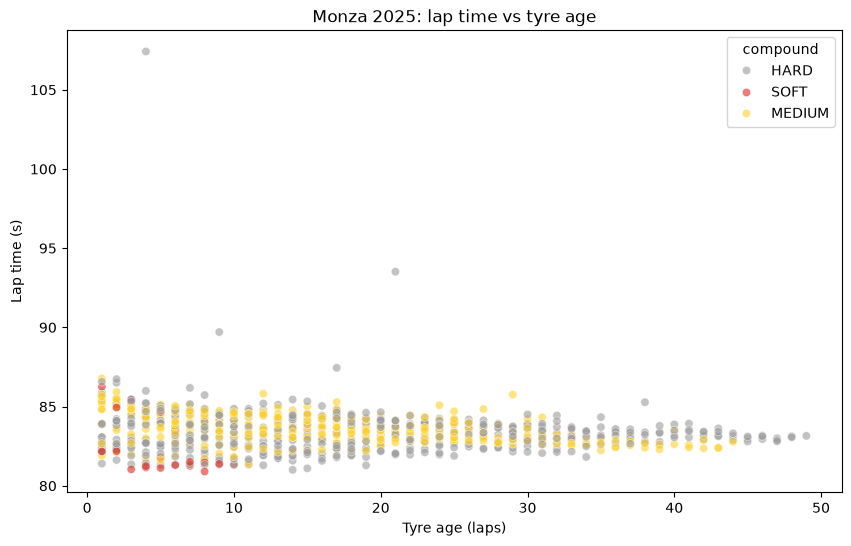

In [8]:
COMPOUND_COLOURS = {"SOFT": "#DA291C", "MEDIUM": "#FFD12E", "HARD": "#9B9B9B"}

monza = laps[(laps["season"] == 2025) & (laps["circuit_name"] == "Monza")]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=monza,
    x="tyre_age_laps",
    y="lap_time_s",
    hue="compound",
    palette=COMPOUND_COLOURS,
    alpha=0.6,
    ax=ax,
)
ax.set_title("Monza 2025: lap time vs tyre age")
ax.set_xlabel("Tyre age (laps)")
ax.set_ylabel("Lap time (s)")
plt.show()

## Removing outlier laps

A lap is an outlier if it is slower than 107% of the same driver's median lap in the same race (an adaptation of the F1 qualifying 107% rule). These are laps slowed by mistakes, local yellow flags or problems that no flag in `fct_laps` captures.

Outlier laps: 1167 (1.4%)


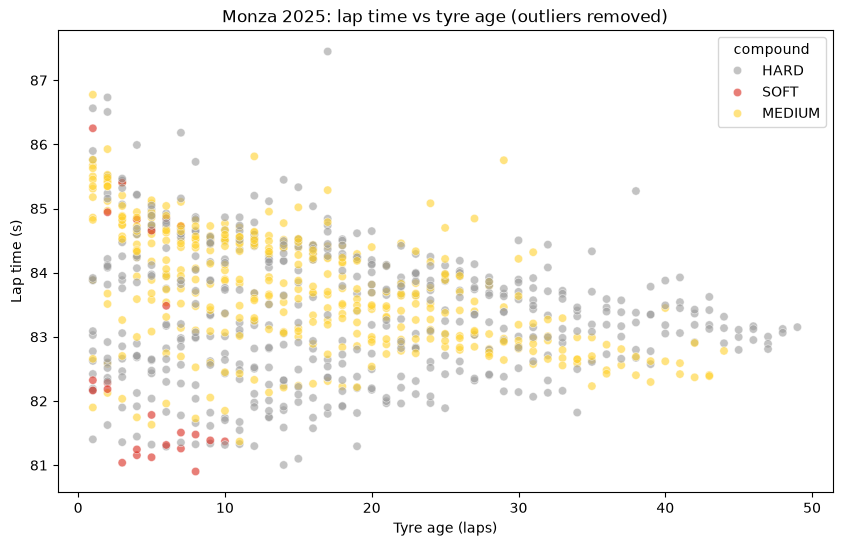

In [9]:
driver_race_median = laps.groupby(["session_key", "driver_number"])["lap_time_s"].transform("median")
laps["is_outlier"] = laps["lap_time_s"] > 1.07 * driver_race_median

print(f"Outlier laps: {laps['is_outlier'].sum()} ({laps['is_outlier'].mean():.1%})")

clean = laps[~laps["is_outlier"]]
monza = clean[(clean["season"] == 2025) & (clean["circuit_name"] == "Monza")]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=monza,
    x="tyre_age_laps",
    y="lap_time_s",
    hue="compound",
    palette=COMPOUND_COLOURS,
    alpha=0.6,
    ax=ax,
)
ax.set_title("Monza 2025: lap time vs tyre age (outliers removed)")
ax.set_xlabel("Tyre age (laps)")
ax.set_ylabel("Lap time (s)")
plt.show()

## One driver: fuel and tyres

Max Verstappen at Monza 2025: mediums until lap 37, then hards. With a single driver the differences between cars disappear, leaving fuel burn and tyre wear.

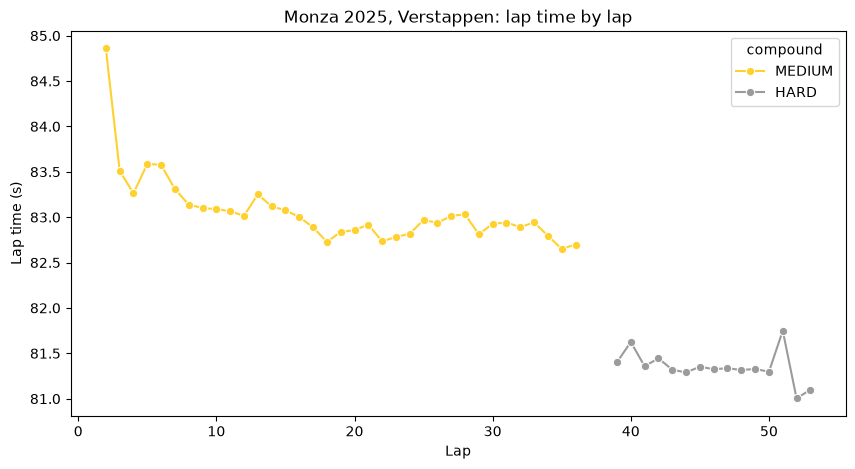

In [10]:
ver = monza[monza["driver_code"] == "VER"].sort_values("lap_number")

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=ver,
    x="lap_number",
    y="lap_time_s",
    hue="compound",
    palette=COMPOUND_COLOURS,
    marker="o",
    ax=ax,
)
ax.set_title("Monza 2025, Verstappen: lap time by lap")
ax.set_xlabel("Lap")
ax.set_ylabel("Lap time (s)")
plt.show()

## Separating fuel and tyre wear

A linear regression on all drivers at Monza 2025:

`lap_time = driver + fuel_effect × lap_number + compound + degradation_compound × tyre_age`

- **driver**: one term per driver, absorbing the pace of each car;
- **lap_number**: fuel burn (plus track evolution), the same for everyone;
- **compound**: pace of each compound when new;
- **compound × tyre_age**: degradation rate of each compound, in seconds per lap of tyre age.

Fuel and tyre age grow together within a stint; pit stops reset the tyre age while the lap number keeps growing, which lets the model tell them apart.

In [11]:
model = smf.ols(
    "lap_time_s ~ C(driver_code) + lap_number + C(compound) + C(compound):tyre_age_laps",
    data=monza,
).fit()

print(f"Laps: {int(model.nobs)}, R²: {model.rsquared:.2f}")

estimates = model.params.to_frame("estimate_s").join(
    model.conf_int().rename(columns={0: "ci_low_s", 1: "ci_high_s"})
)
estimates[~estimates.index.str.startswith("C(driver_code)")].round(3)

Laps: 914, R²: 0.86


,estimate_s,ci_low_s,ci_high_s
Intercept,84.915,84.781,85.049
C(compound)[T.MEDIUM],-0.100,-0.207,0.007
C(compound)[T.SOFT],0.051,-0.307,0.408
lap_number,-0.062,-0.065,-0.060
C(compound)[HARD]:tyre_age_laps,0.014,0.010,0.018
C(compound)[MEDIUM]:tyre_age_laps,0.018,0.013,0.022
C(compound)[SOFT]:tyre_age_laps,0.019,-0.045,0.082


## Degradation in every race

The same model fitted on each race separately. A compound is included in a race only if it was used for at least 50 representative laps: below that, the estimate is too uncertain.

In [17]:
MIN_LAPS_PER_COMPOUND = 50


def fit_degradation(race):
    """Fit the fuel and tyre model on one race and return one row per compound.

    Returns None when fuel and tyre age cannot be separated in this race.
    """
    counts = race["compound"].value_counts()
    race = race[race["compound"].isin(counts[counts >= MIN_LAPS_PER_COMPOUND].index)]
    if race.empty:
        return pd.DataFrame()

    model = smf.ols(
        "lap_time_s ~ C(driver_code) + lap_number + C(compound) + C(compound):tyre_age_laps",
        data=race,
    )
    # Rank-deficient design: fuel and tyre age grow together for every driver
    # (e.g. everybody changed tyres on the same lap under a red flag), so the
    # estimates would not be identifiable
    if np.linalg.matrix_rank(model.exog) < model.exog.shape[1]:
        return None

    fit = model.fit()
    ci = fit.conf_int()

    rows = []
    for compound in race["compound"].unique():
        term = f"C(compound)[{compound}]:tyre_age_laps"
        rows.append(
            {
                "compound": compound,
                "degradation_s_per_lap": fit.params[term],
                "ci_low": ci.loc[term, 0],
                "ci_high": ci.loc[term, 1],
                "laps": int((race["compound"] == compound).sum()),
                "fuel_s_per_lap": fit.params["lap_number"],
            }
        )
    return pd.DataFrame(rows)


results = []
skipped = []
for (session_key, season, circuit), race in clean.groupby(["session_key", "season", "circuit_name"]):
    fitted = fit_degradation(race)
    if fitted is None:
        skipped.append(f"{season} {circuit}")
        continue
    fitted.insert(0, "circuit_name", circuit)
    fitted.insert(0, "season", season)
    fitted.insert(0, "session_key", session_key)
    results.append(fitted)

degradation = pd.concat(results, ignore_index=True)

print(f"Races: {degradation['session_key'].nunique()}, estimates: {len(degradation)}")
print(f"Skipped (not identifiable): {', '.join(skipped)}")
degradation.head(10).round(3)

Races: 85, estimates: 198
Skipped (not identifiable): 2025 Melbourne, 2025 Spa-Francorchamps, 2025 Silverstone


,session_key,season,circuit_name,compound,degradation_s_per_lap,ci_low,ci_high,laps,fuel_s_per_lap
0,7779,2023,Jeddah,HARD,0.007,-0.003,0.018,464,-0.062
1,7779,2023,Jeddah,MEDIUM,0.005,-0.011,0.021,328,-0.062
2,7787,2023,Melbourne,HARD,-0.018,-0.039,0.004,645,-0.044
3,7787,2023,Melbourne,MEDIUM,0.039,0.014,0.064,79,-0.044
4,7953,2023,Sakhir,SOFT,0.184,0.166,0.202,410,-0.086
5,7953,2023,Sakhir,HARD,0.142,0.130,0.155,524,-0.086
6,9070,2023,Baku,HARD,0.053,0.038,0.068,696,-0.099
7,9070,2023,Baku,MEDIUM,0.137,0.085,0.189,147,-0.099
8,9078,2023,Miami,HARD,0.035,0.029,0.040,793,-0.058
9,9078,2023,Miami,MEDIUM,0.060,0.045,0.075,295,-0.058


Races where fuel and tyre age cannot be separated are skipped: 2025 Melbourne, Spa-Francorchamps and Silverstone. All three started wet and drivers switched to dry tyres almost on the same lap, so for dry compounds tyre age and lap number grow together for everyone.

Mixed-weather races that are kept can still be biased, because a drying track also makes laps faster.

## Which circuits are hardest on tyres?

Median degradation per circuit over 2023-2026, for mediums and hards (softs have too few reliable estimates).

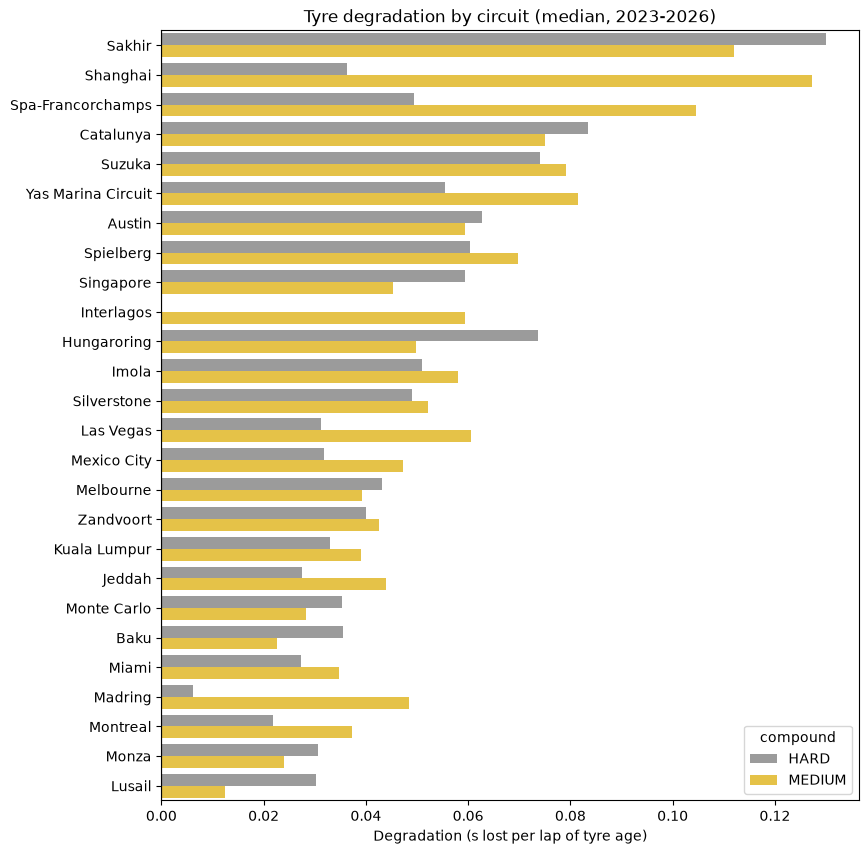

In [ ]:
race_compounds = degradation[degradation["compound"].isin(["MEDIUM", "HARD"])]

circuit_order = (
    race_compounds.groupby("circuit_name")["degradation_s_per_lap"]
    .median()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(9, 10))
sns.barplot(
    data=race_compounds,
    x="degradation_s_per_lap",
    y="circuit_name",
    hue="compound",
    palette=COMPOUND_COLOURS,
    estimator="median",
    errorbar=None,
    order=circuit_order,
    ax=ax,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Tyre degradation by circuit (median, 2023-2026)")
ax.set_xlabel("Degradation (s lost per lap of tyre age)")
ax.set_ylabel("")
fig.savefig("../docs/images/degradation_by_circuit.png", dpi=150, bbox_inches="tight")
plt.show()

## Did the 2026 regulations change tyre degradation?

The seasons do not include the same circuits, so comparing season averages would mix a regulation effect with a calendar effect. The comparison is paired instead: for each circuit and compound, the 2026 estimate against the median of 2023-2025 on the same circuit, using only pairs available in both periods.

In [22]:
eras = race_compounds.assign(
    era=np.where(race_compounds["season"] == 2026, "2026", "2023-2025")
)

paired = (
    eras.groupby(["circuit_name", "compound", "era"])["degradation_s_per_lap"]
    .median()
    .unstack("era")
    .dropna()
)
paired["change"] = paired["2026"] - paired["2023-2025"]

print(f"Circuit and compound pairs: {len(paired)}")
paired.groupby("compound")["change"].describe().round(3)

Circuit and compound pairs: 31


,count,mean,std,min,25%,50%,75%,max
compound,,,,,,,,
HARD,14.0,0.001,0.039,-0.084,-0.021,0.006,0.022,0.062
MEDIUM,17.0,-0.011,0.049,-0.074,-0.042,-0.013,0.013,0.119


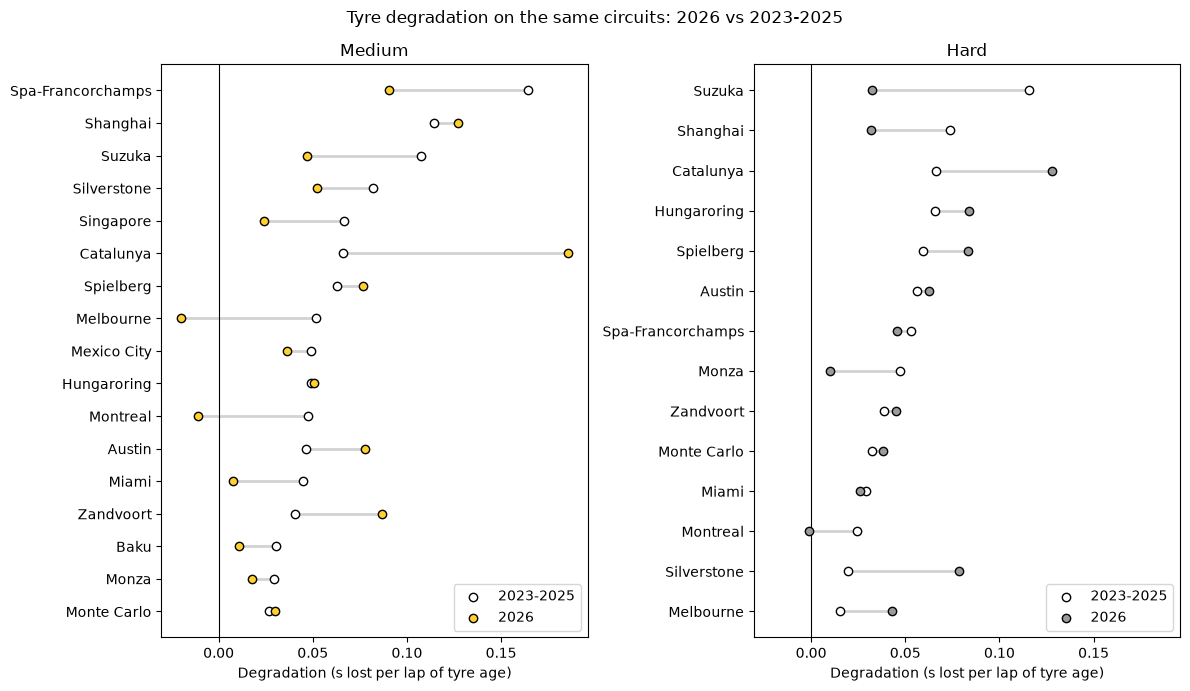

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharex=True)

for ax, compound in zip(axes, ["MEDIUM", "HARD"]):
    data = paired.xs(compound, level="compound").sort_values("2023-2025")
    y = range(len(data))

    ax.hlines(y, data["2023-2025"], data["2026"], color="lightgrey", linewidth=2)
    ax.scatter(
        data["2023-2025"], y, facecolor="white", edgecolor="black", label="2023-2025", zorder=3
    )
    ax.scatter(
        data["2026"], y, color=COMPOUND_COLOURS[compound], edgecolor="black", label="2026", zorder=3
    )

    ax.set_yticks(list(y))
    ax.set_yticklabels(data.index)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(compound.title())
    ax.set_xlabel("Degradation (s lost per lap of tyre age)")
    ax.legend(loc="lower right")

fig.suptitle("Tyre degradation on the same circuits: 2026 vs 2023-2025")
fig.tight_layout()
fig.savefig("../images/degradation_2026_vs_before.png", dpi=150, bbox_inches="tight")
plt.show()

### Findings

- **No systematic change in 2026.** On the same circuits, the average change in degradation is +0.001 s/lap for hards (14 circuits) and -0.011 s/lap for mediums (17 circuits), against a standard deviation of 0.04-0.05 s/lap. The ratio between the mean change and its standard error is about 0.1 for hards and 0.9 for mediums, well below the level needed to call it an effect.
- **Circuit-level changes go both ways** and are larger than the average effect. The most credible ones are consistent across compounds: Barcelona degrades more in 2026, Suzuka much less.
- **Limits.** 2026 has a single race per circuit, and a single-race estimate has an uncertainty comparable to the changes observed. Some 2026 estimates are below zero (Melbourne and Montreal on mediums), which is not physical and points to too few laps or an improving track. The Silverstone baseline only includes 2023 and 2024. 2026 changed both cars and tyres (narrower), so the comparison measures their combined effect.